Angelyn Nathasya Br Marpaung 

## Libraries

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image

from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Reshape, UpSampling2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

from skimage.metrics import structural_similarity as ssim

print(f"Libraries imported successfully!")


Libraries imported successfully!


## Load dataset

Seluruh gambar dikonversi menjadi citra grayscale dan diubah ukurannya menjadi 28 × 28 piksel agar memiliki dimensi yang seragam.

In [2]:
dataset_path = "Dataset"
classes = ["car", "plane"]

images = []
labels = []

valid_extensions = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")

for folder in ["train", "test"]:
    for label, cls in enumerate(classes):

        folder_path = os.path.join(
            dataset_path,
            folder,
            cls
        )

        if not os.path.isdir(folder_path):
            raise FileNotFoundError(
                f"Folder tidak ditemukan: {folder_path}"
            )

        for file in sorted(os.listdir(folder_path)):

            if not file.lower().endswith(valid_extensions):
                continue

            img_path = os.path.join(folder_path, file)

            with Image.open(img_path) as img:
                img = img.convert("L")
                img = img.resize((28, 28))

                images.append(np.array(img))
                labels.append(label)

In [3]:
X = np.array(images)
y = np.array(labels)

print("Jumlah seluruh gambar:", len(X))
print("Bentuk X:", X.shape)
print("Bentuk y:", y.shape)
print("Jumlah gambar Car:", np.sum(y == 0))
print("Jumlah gambar Plane:", np.sum(y == 1))

Jumlah seluruh gambar: 16024
Bentuk X: (16024, 28, 28)
Bentuk y: (16024,)
Jumlah gambar Car: 8012
Jumlah gambar Plane: 8012


## Scaling Data

Karena pixel gambarnya bernilai 0–255. Jadi, di scaling menjadi 0–1 dengan  membagi setiap nilai piksel terhadap 255

In [4]:
X = X.astype("float32")/255.0

# Tambahkan channel dimension untuk grayscale
X = np.expand_dims(X, axis=-1)

print("Shape X:", X.shape)
print("Minimum pixel:", X.min())
print("Maximum pixel:", X.max())

Shape X: (16024, 28, 28, 1)
Minimum pixel: 0.0
Maximum pixel: 1.0


## Contoh Gambar

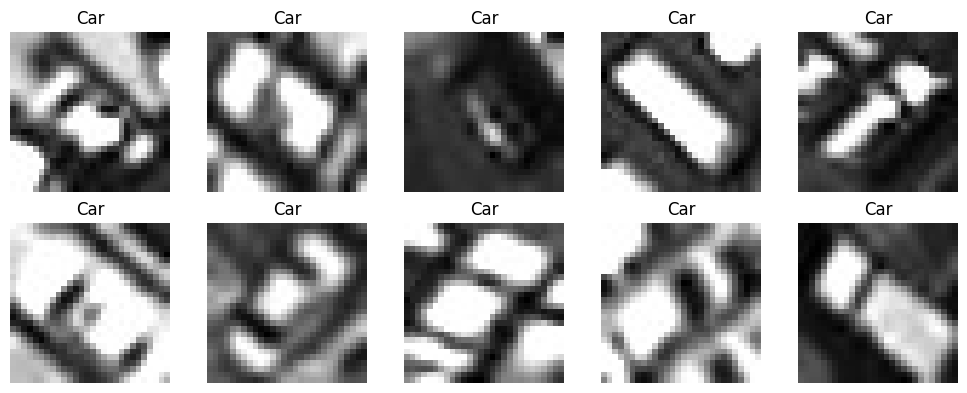

In [5]:
class_names = ["Car","Plane"]

plt.figure(figsize=(10,4))

for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(X[i], cmap="gray")
    plt.title(class_names[y[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

## Split Data (Train : Val : Test = 80 : 10 : 10)

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.10, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=1/9, stratify=y_train, random_state=42)

print("Training :", X_train.shape)
print("Validation :", X_val.shape)
print("Testing :", X_test.shape)

Training : (12818, 28, 28, 1)
Validation : (1603, 28, 28, 1)
Testing : (1603, 28, 28, 1)


## Baseline Model

In [7]:
def build_baseline_autoencoder():

    input_img = Input(shape=(28,28,1))

    # Encoder
    x = Conv2D(
        32,
        (3,3),
        activation='relu',
        padding='same'
    )(input_img)

    x = MaxPooling2D(
        (2,2),
        padding='same'
    )(x)

    x = Flatten()(x)

    latent = Dense(
        128,
        activation='relu'
    )(x)

    # Decoder
    x = Dense(
        14*14*32
    )(latent)

    x = Reshape(
        (14,14,32)
    )(x)

    x = UpSampling2D((2,2))(x)

    x = Conv2D(
        32,
        (3,3),
        activation='relu',
        padding='same'
    )(x)

    output = Conv2D(
        1,
        (3,3),
        activation='sigmoid',
        padding='same'
    )(x)

    return Model(
        input_img,
        output,
        name="Baseline_Autoencoder"
    )

### Training

In [8]:
baseline_model = build_baseline_autoencoder()

# Compile model
baseline_model.compile(
    optimizer='adam',
    loss='binary_crossentropy'
)

history_baseline = baseline_model.fit(
    X_train,
    X_train,
    validation_data=(X_val, X_val),
    epochs=50,
    batch_size=32,
    shuffle=True
)




Epoch 1/50

401/401 [==============================] - 6s 14ms/step - loss: 0.5296 - val_loss: 0.4974
Epoch 2/50
401/401 [==============================] - 5s 13ms/step - loss: 0.4836 - val_loss: 0.4829
Epoch 3/50
401/401 [==============================] - 5s 13ms/step - loss: 0.4741 - val_loss: 0.4768
Epoch 4/50
401/401 [==============================] - 5s 13ms/step - loss: 0.4696 - val_loss: 0.4745
Epoch 5/50
401/401 [==============================] - 5s 13ms/step - loss: 0.4678 - val_loss: 0.4738
Epoch 6/50
401/401 [==============================] - 5s 13ms/step - loss: 0.4664 - val_loss: 0.4739
Epoch 7/50
401/401 [==============================] - 5s 13ms/step - loss: 0.4655 - val_loss: 0.4718
Epoch 8/50
401/401 [==============================] - 5s 13ms/step - loss: 0.4645 - val_loss: 0.4712
Epoch 9/50
401/401 [==============================] - 6s 14ms/step - loss: 0.4638 - val_loss: 0.4702
Epoch 10/50
401/401 [==============================] - 5s 13ms/step - loss: 0.4631 - va

### Prediksi

In [9]:
decoded_images_baseline = baseline_model.predict(X_test)

51/51 [==============================] - 0s 3ms/step


### Evaluasi SSIM

In [10]:
baseline_ssim = []

for i in range(len(X_test)):
    score = ssim(
        X_test[i].squeeze(),
        decoded_images_baseline[i].squeeze(),
        data_range=1.0
    )

    baseline_ssim.append(score)

baseline_ssim = np.mean(baseline_ssim)
print("Average SSIM :", baseline_ssim)

Average SSIM : 0.685014956893552


### Visualisasi

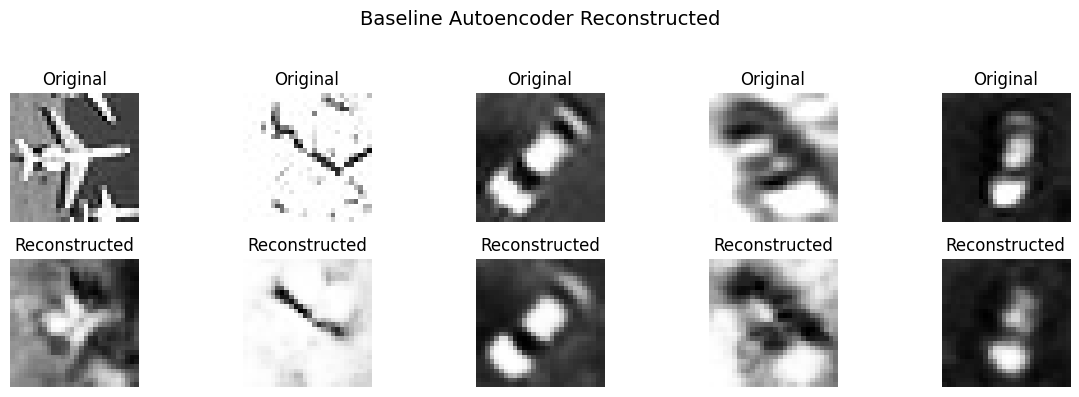

In [11]:
plt.figure(figsize=(12,4))
for i in range(5):
    plt.subplot(2,5,i+1)
    plt.imshow(X_test[i].squeeze(), cmap="gray")
    plt.title("Original")
    plt.axis("off")

    plt.subplot(2,5,i+6)
    plt.imshow(decoded_images_baseline[i].squeeze(), cmap="gray")
    plt.title("Reconstructed")
    plt.axis("off")
plt.suptitle("Baseline Autoencoder Reconstructed", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### Visualisasi Train Loss vs Val Loss

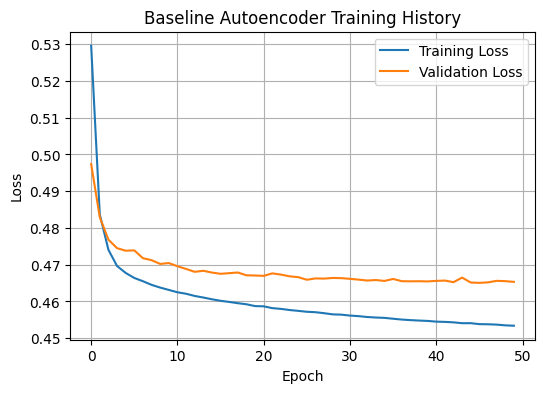

In [12]:
plt.figure(figsize=(6,4))
plt.plot(history_baseline.history["loss"], label="Training Loss")
plt.plot(history_baseline.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline Autoencoder Training History")
plt.legend()
plt.grid(True)
plt.show()

## Modifikasi Arsitektur Autoencoder

In [13]:
def build_modified_autoencoder():

    input_img = Input(shape=(28,28,1))

    # Encoder
    x = Conv2D(
        32,
        (3,3),
        activation='relu',
        padding='same'
    )(input_img)

    x = Conv2D(
        64,
        (3,3),
        activation='relu',
        padding='same'
    )(x)

    x = MaxPooling2D(
        (2,2),
        padding='same'
    )(x)

    x = Flatten()(x)

    latent = Dense(
        128,
        activation='relu'
    )(x)

    # Decoder
    x = Dense(
        14*14*64,
        activation='relu'
    )(latent)

    x = Reshape(
        (14,14,64)
    )(x)

    x = UpSampling2D((2,2))(x)

    x = Conv2D(
        64,
        (3,3),
        activation='relu',
        padding='same'
    )(x)

    x = Conv2D(
        32,
        (3,3),
        activation='relu',
        padding='same'
    )(x)

    output = Conv2D(
        1,
        (3,3),
        activation='sigmoid',
        padding='same'
    )(x)

    model = Model(
        input_img,
        output,
        name="Modified_Autoencoder"
    )

    return model

### Training

In [14]:
modified_autoencoder = build_modified_autoencoder()

# Compile model
modified_autoencoder.compile(
    optimizer= Adam(learning_rate=0.0005),
    loss="binary_crossentropy"
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_modified = modified_autoencoder.fit(
    X_train,
    X_train,
    validation_data=(X_val, X_val),
    epochs=100,
    batch_size=16,
    callbacks=[early_stop],
    shuffle=True
)

Epoch 1/100
802/802 [==============================] - 21s 25ms/step - loss: 0.5048 - val_loss: 0.4724
Epoch 2/100
802/802 [==============================] - 19s 24ms/step - loss: 0.4585 - val_loss: 0.4602
Epoch 3/100
802/802 [==============================] - 19s 24ms/step - loss: 0.4504 - val_loss: 0.4554
Epoch 4/100
802/802 [==============================] - 20s 24ms/step - loss: 0.4475 - val_loss: 0.4527
Epoch 5/100
802/802 [==============================] - 20s 25ms/step - loss: 0.4459 - val_loss: 0.4522
Epoch 6/100
802/802 [==============================] - 19s 24ms/step - loss: 0.4446 - val_loss: 0.4503
Epoch 7/100
802/802 [==============================] - 19s 24ms/step - loss: 0.4436 - val_loss: 0.4504
Epoch 8/100
802/802 [==============================] - 19s 24ms/step - loss: 0.4426 - val_loss: 0.4497
Epoch 9/100
802/802 [==============================] - 20s 24ms/step - loss: 0.4420 - val_loss: 0.4491
Epoch 10/100
802/802 [==============================] - 19s 24ms/step - l

### Prediksi

In [15]:
decoded_images_modified = modified_autoencoder.predict(X_test)

51/51 [==============================] - 0s 8ms/step


### Evaluasi SSIM

In [16]:
ssim_scores_modified  = []

for i in range(len(X_test)):
    score = ssim(
        X_test[i].squeeze(),
        decoded_images_modified[i].squeeze(),
        data_range=1.0
    )

    ssim_scores_modified .append(score)

modified_ssim = np.mean(ssim_scores_modified)
print("Average SSIM :", modified_ssim)

Average SSIM : 0.8244153479315961


### Visualisasi

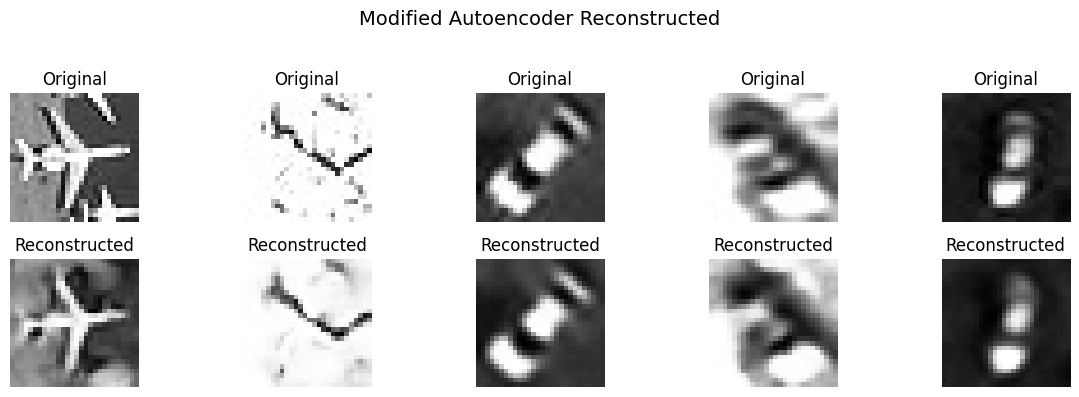

In [17]:
plt.figure(figsize=(12, 4))
for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i].squeeze(), cmap="gray")
    plt.title("Original")
    plt.axis("off")

    plt.subplot(2, 5, i + 6)
    plt.imshow(decoded_images_modified[i].squeeze(), cmap="gray")
    plt.title("Reconstructed")
    plt.axis("off")
plt.suptitle("Modified Autoencoder Reconstructed", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### Visualisasi Train Loss vs Val Loss

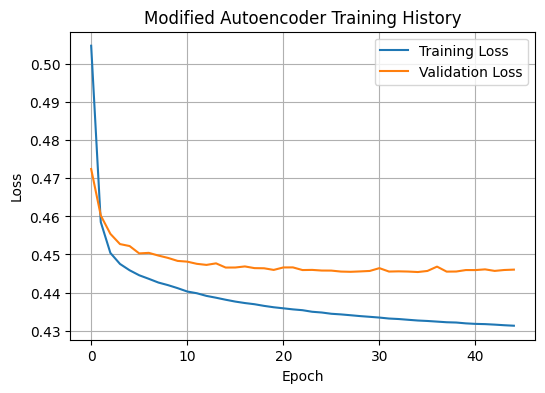

In [18]:
plt.figure(figsize=(6,4))
plt.plot(history_modified.history["loss"], label="Training Loss")
plt.plot(history_modified.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Modified Autoencoder Training History")
plt.legend()
plt.grid(True)
plt.show()

## Modified Autoencoder + Hyperparameter Tuning

Setelah diperoleh arsitektur Autoencoder hasil modifikasi, dilakukan proses hyperparameter tuning untuk meningkatkan kualitas rekonstruksi citra. Pada tahap ini arsitektur model dipertahankan, yang di ubah hanya learning rate, batch size, dan jumlah epoch. Setiap kombinasi hyperparameter dilatih menggunakan data yang sama, kemudian dievaluasi menggunakan nilai SSIM pada data test.

Alasan Pemilihan Hyperparameter:

-Learning Rate = menentukan besar langkah update bobot. Semakin kecil nilainya,maka proses training akan lebih stabil namun membutuhkan waktu lebih lama.

-Batch Size = menentukan jumlah data yang diproses pada setiap iterasi. Semakin kecil batch sizenya, maka update menjadi lebih sering sehingga model berpotensi mempelajari pola data dengan lebih baik.

-Epoch = menentukan jumlah pengulangan training terhadap seluruh data train. Penambahan epoch memberikan kesempatan model untuk mencapai konvergensi yang lebih baik, selama tidak menyebabkan overfitting.

### Fungsi SSIM

In [19]:
def calculate_ssim(original, reconstructed):
    scores = []

    for i in range(len(original)):
        score = ssim(
            original[i].squeeze(),
            reconstructed[i].squeeze(),
            data_range=1.0
        )
        scores.append(score)
    return np.mean(scores)

### Trail 1

In [20]:
trial1 = build_modified_autoencoder()

trial1.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy"
)

history_trial1 = trial1.fit(
    X_train,
    X_train,
    validation_data=(X_val, X_val),
    epochs=50,
    batch_size=32,
    callbacks=[early_stop],
    shuffle=True
)

decoded_trial1 = trial1.predict(X_test)

ssim_trial1 = calculate_ssim(
    X_test,
    decoded_trial1
)

Epoch 1/50
401/401 [==============================] - 14s 33ms/step - loss: 0.5293 - val_loss: 0.4920
Epoch 2/50
401/401 [==============================] - 13s 33ms/step - loss: 0.4741 - val_loss: 0.4737
Epoch 3/50
401/401 [==============================] - 13s 34ms/step - loss: 0.4640 - val_loss: 0.4671
Epoch 4/50
401/401 [==============================] - 13s 33ms/step - loss: 0.4604 - val_loss: 0.4658
Epoch 5/50
401/401 [==============================] - 13s 33ms/step - loss: 0.4583 - val_loss: 0.4639
Epoch 6/50
401/401 [==============================] - 13s 33ms/step - loss: 0.4568 - val_loss: 0.4628
Epoch 7/50
401/401 [==============================] - 13s 32ms/step - loss: 0.4556 - val_loss: 0.4618
Epoch 8/50
401/401 [==============================] - 13s 33ms/step - loss: 0.4547 - val_loss: 0.4611
Epoch 9/50
401/401 [==============================] - 13s 32ms/step - loss: 0.4536 - val_loss: 0.4605
Epoch 10/50
401/401 [==============================] - 13s 33ms/step - loss: 0.452

### Trail 2

In [21]:
trial2 = build_modified_autoencoder()

trial2.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss="binary_crossentropy"
)

history_trial2 = trial2.fit(
    X_train,
    X_train,
    validation_data=(X_val, X_val),
    epochs=50,
    batch_size=32,
    callbacks=[early_stop],
    shuffle=True
)

decoded_trial2 = trial2.predict(X_test)

ssim_trial2 = calculate_ssim(
    X_test,
    decoded_trial2
)

Epoch 1/50
401/401 [==============================] - 14s 33ms/step - loss: 0.5323 - val_loss: 0.4838
Epoch 2/50
401/401 [==============================] - 13s 33ms/step - loss: 0.4684 - val_loss: 0.4650
Epoch 3/50
401/401 [==============================] - 13s 32ms/step - loss: 0.4553 - val_loss: 0.4577
Epoch 4/50
401/401 [==============================] - 13s 32ms/step - loss: 0.4498 - val_loss: 0.4540
Epoch 5/50
401/401 [==============================] - 13s 32ms/step - loss: 0.4470 - val_loss: 0.4519
Epoch 6/50
401/401 [==============================] - 13s 32ms/step - loss: 0.4452 - val_loss: 0.4506
Epoch 7/50
401/401 [==============================] - 13s 32ms/step - loss: 0.4442 - val_loss: 0.4499
Epoch 8/50
401/401 [==============================] - 13s 33ms/step - loss: 0.4433 - val_loss: 0.4492
Epoch 9/50
401/401 [==============================] - 13s 32ms/step - loss: 0.4425 - val_loss: 0.4485
Epoch 10/50
401/401 [==============================] - 13s 32ms/step - loss: 0.441

### Trial 3

In [22]:
trial3 = build_modified_autoencoder()

trial3.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss="binary_crossentropy"
)

history_trial3 = trial3.fit(
    X_train,
    X_train,
    validation_data=(X_val, X_val),
    epochs=100,
    batch_size=16,
    callbacks=[early_stop],
    shuffle=True
)

decoded_trial3 = trial3.predict(X_test)

ssim_trial3 = calculate_ssim(
    X_test,
    decoded_trial3
)

Epoch 1/100
802/802 [==============================] - 20s 23ms/step - loss: 0.5094 - val_loss: 0.4777
Epoch 2/100
802/802 [==============================] - 18s 22ms/step - loss: 0.4638 - val_loss: 0.4636
Epoch 3/100
802/802 [==============================] - 18s 23ms/step - loss: 0.4556 - val_loss: 0.4596
Epoch 4/100
802/802 [==============================] - 18s 22ms/step - loss: 0.4528 - val_loss: 0.4584
Epoch 5/100
802/802 [==============================] - 18s 22ms/step - loss: 0.4511 - val_loss: 0.4576
Epoch 6/100
802/802 [==============================] - 18s 23ms/step - loss: 0.4500 - val_loss: 0.4561
Epoch 7/100
802/802 [==============================] - 18s 22ms/step - loss: 0.4489 - val_loss: 0.4564
Epoch 8/100
802/802 [==============================] - 18s 22ms/step - loss: 0.4478 - val_loss: 0.4545
Epoch 9/100
802/802 [==============================] - 18s 22ms/step - loss: 0.4471 - val_loss: 0.4541
Epoch 10/100
802/802 [==============================] - 18s 23ms/step - l

### Compare

In [23]:
comparison_tuning = pd.DataFrame({
    "Trial":[
        "Trial 1",
        "Trial 2",
        "Trial 3"
    ],

    "Learning Rate":[
        0.001,
        0.0005,
        0.0005
    ],

    "Batch Size":[
        32,
        32,
        16
    ],

    "Epoch":[
        50,
        50,
        100
    ],

    "Train Loss":[
        history_trial1.history["loss"][-1],
        history_trial2.history["loss"][-1],
        history_trial3.history["loss"][-1]
    ],

    "Validation Loss":[
        history_trial1.history["val_loss"][-1],
        history_trial2.history["val_loss"][-1],
        history_trial3.history["val_loss"][-1]
    ],

    "Average SSIM":[
        ssim_trial1,
        ssim_trial2,
        ssim_trial3
    ]
})

comparison_tuning

,Trial,Learning Rate,Batch Size,Epoch,Train Loss,Validation Loss,Average SSIM
0,Trial 1,0.0010,32,50,0.441269,0.457010,0.749236
1,Trial 2,0.0005,32,50,0.430886,0.444028,0.834427
2,Trial 3,0.0005,16,100,0.435307,0.450347,0.790132


### Best Model

In [24]:
best_trial = comparison_tuning.loc[
    comparison_tuning["Average SSIM"].idxmax()
]

print(best_trial)

Trial               Trial 2
Learning Rate        0.0005
Batch Size               32
Epoch                    50
Train Loss         0.430886
Validation Loss    0.444028
Average SSIM       0.834427
Name: 1, dtype: object


### Visualisasi Hasil Hyperparameter Tuning

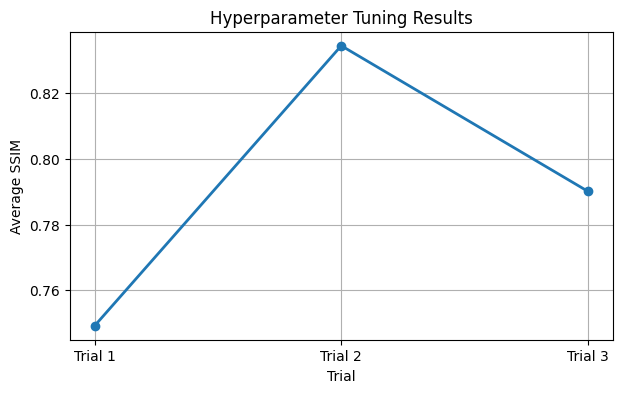

In [25]:
plt.figure(figsize=(7,4))
plt.plot(comparison_tuning["Trial"], comparison_tuning["Average SSIM"], marker='o', linewidth=2)
plt.title("Hyperparameter Tuning Results")
plt.xlabel("Trial")
plt.ylabel("Average SSIM")
plt.grid(True)
plt.show()

### Visualisasi Best Model

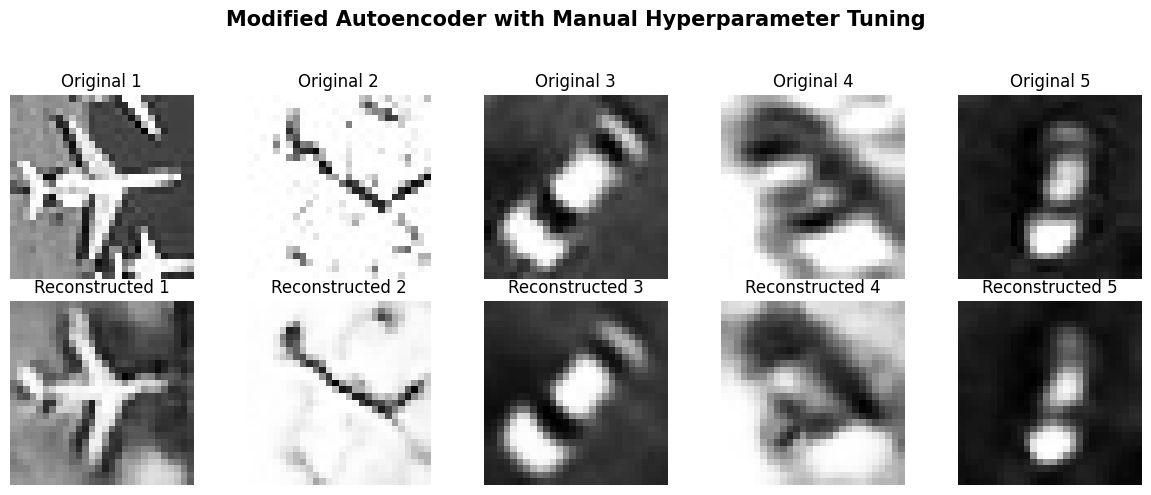

In [26]:
plt.figure(figsize=(12,5))
for i in range(5):
    plt.subplot(2,5,i+1)
    plt.imshow(X_test[i].squeeze(), cmap="gray")
    plt.title(f"Original {i+1}")
    plt.axis("off")


    plt.subplot(2,5,i+6)
    plt.imshow(decoded_trial3[i].squeeze(), cmap="gray")
    plt.title(f"Reconstructed {i+1}")
    plt.axis("off")
plt.suptitle("Modified Autoencoder with Manual Hyperparameter Tuning", fontsize=15, fontweight="bold")
plt.tight_layout(rect=[0,0,1,0.94])
plt.show()

## Baseline Autoencoder vs Modified Autoencoder

Modifikasi Arsitektur

Arsitektur Autoencoder dimodifikasi dengan menambahkan satu lapisan Conv2D pada encoder dan satu lapisan Conv2D pada decoder. Penambahan lapisan konvolusi bertujuan meningkatkan kemampuan model dalam mengekstraksi fitur citra pada berbagai tingkat abstraksi. Lapisan konvolusi pertama mempelajari pola lokal seperti tepi dan tekstur, sedangkan lapisan berikutnya mempelajari representasi fitur yang lebih kompleks. Dengan demikian, informasi yang diteruskan ke ruang laten menjadi lebih representatif sehingga proses rekonstruksi citra menghasilkan kualitas yang lebih baik.

Hyperparameter Tuning

Selain modifikasi arsitektur, dilakukan penyesuaian beberapa hyperparameter, yaitu learning rate, batch size, dan jumlah epoch. Learning rate diturunkan dari 0,001 menjadi 0,0005 agar proses optimisasi berlangsung lebih stabil dan mengurangi risiko melewati titik minimum. Batch size diperkecil dari 32 menjadi 16 sehingga pembaruan bobot dilakukan lebih sering dan model dapat mempelajari karakteristik data dengan lebih baik. Jumlah epoch ditingkatkan dari 50 menjadi 100 agar model memiliki waktu yang cukup untuk mencapai konvergensi. Kinerja kedua model dibandingkan menggunakan metrik Structural Similarity Index Measure (SSIM) pada data uji. Model dengan nilai SSIM yang lebih tinggi dianggap mampu mempertahankan struktur visual citra dengan lebih baik setelah proses reduksi dimensi dan rekonstruksi.

In [28]:
comparison_model = pd.DataFrame({

    "Model": [
        "Baseline",
        "Modified",
        "Modified + Hyperparameter Tuning"
    ],

    "Train Loss": [
        history_baseline.history["loss"][-1],
        history_modified.history["loss"][-1],
        best_trial["Train Loss"]
    ],

    "Validation Loss": [
        history_baseline.history["val_loss"][-1],
        history_modified.history["val_loss"][-1],
        best_trial["Validation Loss"]
    ],

    "Average SSIM": [
        baseline_ssim,
        modified_ssim,
        best_trial["Average SSIM"]
    ]
})

comparison_model

,Model,Train Loss,Validation Loss,Average SSIM
0,Baseline,0.453392,0.465327,0.685015
1,Modified,0.431308,0.446030,0.824415
2,Modified + Hyperparameter Tuning,0.430886,0.444028,0.834427
